# Used Car Price Analysis and Prediction

## **1. Introduction**

The Used Car Price Analysis and Prediction project uses the Car Dekho dataset to analyze used cars and estimate their selling prices using machine learning.

## **2. Objectives**

- To understand and analyze used car data.
- To clean the dataset and handle missing or duplicate records.
- To visualize car prices and other important features.
- To identify factors that influence used car prices.
- To train a machine learning model to predict selling prices.
- To evaluate the model and build an interactive prediction interface.

## **3. Technologies Used**

- Python
- Google Colab
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Gradio

## **4. Dataset Description**

The dataset contains information about used cars, including car name, manufacturing year, selling price, kilometres driven, fuel type, seller type, transmission, and ownership history.

**Added sections:** optional live web scraping, hypothesis tests (Welch t-test, one-way ANOVA, Pearson correlation), four-model comparison, and a Streamlit interface.

## **5. Importing Required Libraries**

In this step, we import Python libraries required for data manipulation, numerical calculations, data visualization, and machine learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

print("All libraries imported successfully!")

All libraries imported successfully!


## **6. Beginner-Friendly Live CarDekho Scraping (Optional)**

This section tries to read a publicly accessible listing page with `requests` and parse it with BeautifulSoup. Use only pages you are allowed to access, follow the website's terms and robots rules, and keep requests slow. It does **not** bypass logins, CAPTCHAs, anti-bot checks, or access restrictions. CarDekho may render listings with JavaScript or block automated requests, so the script may return no records. If that happens, use the provided dataset or authorized saved HTML files instead.

In [ ]:
# Install once if needed
%pip -q install beautifulsoup4 requests

from pathlib import Path
import re
import time
import pandas as pd
import requests
from bs4 import BeautifulSoup

OUTPUT_CSV = Path("cardekho_live_scraped_data.csv")

def clean_text(value):
    return re.sub(r"\\s+", " ", str(value or "")).strip()

def scrape_car_listings(page_url):
    # A normal browser-like header; this does not bypass site restrictions.
    headers = {"User-Agent": "Mozilla/5.0 (compatible; StudentResearch/1.0)"}
    response = requests.get(page_url, headers=headers, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    records = []

    # Common listing card patterns. Website HTML may change.
    cards = soup.select("article, .car-listing, .listing-card, [data-testid*='car']")
    for card in cards:
        name_node = card.select_one("h2, h3, [data-testid*='title'], .title, .car-name")
        price_node = card.select_one("[class*='price'], [data-testid*='price'], .price")
        link_node = card.select_one("a[href]")

        name = clean_text(name_node.get_text(" ", strip=True)) if name_node else ""
        price_text = clean_text(price_node.get_text(" ", strip=True)) if price_node else ""
        listing_url = ""
        if link_node:
            from urllib.parse import urljoin
            listing_url = urljoin(page_url, link_node.get("href", ""))

        if name or price_text:
            records.append({
                "name": name,
                "price_text": price_text,
                "listing_url": listing_url
            })

    return pd.DataFrame(records)

print("Paste a publicly accessible CarDekho listing page URL when prompted.")
print("If the site blocks the request or returns no listings, this is expected on some pages.")


In [ ]:
# Run live scraping only when you want to try it.
# This uses a normal HTTP request and does not bypass restrictions.
page_url = input("Paste listing page URL: ").strip()

try:
    scraped_df = scrape_car_listings(page_url)
    print("Listings found:", len(scraped_df))
    if not scraped_df.empty:
        display(scraped_df.head(10))
        scraped_df.to_csv(OUTPUT_CSV, index=False)
        print("Saved:", OUTPUT_CSV.resolve())
    else:
        print("No listings found. The page may use JavaScript or block automated requests.")
except requests.RequestException as error:
    scraped_df = pd.DataFrame()
    print("Could not fetch page:", error)
    print("Continue using the main CSV dataset; scraping is optional.")


In [ ]:
# Optional: parse locally saved HTML files if live scraping is unavailable.
# Place only HTML pages you are authorized to process in this folder.
HTML_DIR = Path("cardekho_authorized_html")
HTML_DIR.mkdir(parents=True, exist_ok=True)

def parse_authorized_html(html_path):
    soup = BeautifulSoup(Path(html_path).read_text(encoding="utf-8", errors="ignore"), "html.parser")
    records = []
    for card in soup.select("article, .car-listing, .listing-card, [data-testid*='car']"):
        name_node = card.select_one("h2, h3, [data-testid*='title'], .title, .car-name")
        price_node = card.select_one("[class*='price'], [data-testid*='price'], .price")
        name = clean_text(name_node.get_text(" ", strip=True)) if name_node else ""
        price = clean_text(price_node.get_text(" ", strip=True)) if price_node else ""
        if name or price:
            records.append({"name": name, "price_text": price, "source_file": Path(html_path).name})
    return records

print("Optional saved-HTML folder:", HTML_DIR.resolve())


**Important integration note:** the existing price-prediction pipeline expects structured columns such as `year`, `selling_price`, `km_driven`, `fuel`, `transmission`, and `owner`. This HTML parser intentionally does not guess those values from unstructured text. Clean/normalize the extracted fields into those columns, or continue with the original Car Dekho CSV dataset for the existing analysis and model sections.

## **6. Loading the Dataset**

The Car Dekho dataset is loaded into a Pandas DataFrame. The dataset contains details about used cars, which will be analyzed in the following steps.

In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving CAR DETAILS FROM CAR DEKHO.csv to CAR DETAILS FROM CAR DEKHO.csv
Dataset loaded successfully!
Dataset shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## **7. Exploring the Dataset**

Dataset exploration helps us understand its structure, columns, data types, and statistical properties before performing data preprocessing.

In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nFirst 10 Records:")
display(df.head(10))

Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,4340,1491,Maruti Swift Dzire VDI,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,4340.0,NaN,NaN,NaN,2013.090783,4.215344,1992.0,2011.0,2014.0,2016.0,2020.0
selling_price,4340.0,NaN,NaN,NaN,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,NaN,NaN,NaN,66215.777419,46644.102194,1.0,35000.0,60000.0,90000.0,806599.0
fuel,4340,5,Diesel,2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,4340,3,Individual,3244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,4340,2,Manual,3892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,4340,5,First Owner,2832,NaN,NaN,NaN,NaN,NaN,NaN,NaN



First 10 Records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner
9,Maruti Celerio Green VXI,2017,365000,78000,CNG,Individual,Manual,First Owner


## **8. Data Cleaning and Preprocessing**

Data cleaning improves dataset quality by removing duplicate records, handling missing values, correcting data types, and removing invalid values.

In [4]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip().str.lower()

# Convert numerical columns
for col in ["year", "selling_price", "km_driven"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check missing values
print("Missing values before cleaning:")
display(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing essential values
df = df.dropna(
    subset=["name", "year", "selling_price", "km_driven"]
)

# Remove invalid values
df = df[
    (df["selling_price"] > 0) &
    (df["km_driven"] >= 0) &
    (df["year"] >= 1980) &
    (df["year"] <= 2026)
].copy()

print("Dataset shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
display(df.isnull().sum())

display(df.head())

Missing values before cleaning:


,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


Dataset shape after cleaning: (3577, 8)

Missing values after cleaning:


,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## **9. Feature Engineering**

Feature engineering creates additional useful variables from existing data. In this project, car age and car brand are extracted to support further analysis.

In [5]:
# Calculate car age
df["car_age"] = 2026 - df["year"]

# Extract brand from car name
df["brand"] = df["name"].astype(str).str.split().str[0]

print("New features created successfully!")

display(df[[
    "name",
    "brand",
    "year",
    "car_age",
    "selling_price"
]].head(10))

New features created successfully!


,name,brand,year,car_age,selling_price
0,Maruti 800 AC,Maruti,2007,19,60000
1,Maruti Wagon R LXI Minor,Maruti,2007,19,135000
2,Hyundai Verna 1.6 SX,Hyundai,2012,14,600000
3,Datsun RediGO T Option,Datsun,2017,9,250000
4,Honda Amaze VX i-DTEC,Honda,2014,12,450000
5,Maruti Alto LX BSIII,Maruti,2007,19,140000
6,Hyundai Xcent 1.2 Kappa S,Hyundai,2016,10,550000
7,Tata Indigo Grand Petrol,Tata,2014,12,240000
8,Hyundai Creta 1.6 VTVT S,Hyundai,2015,11,850000
9,Maruti Celerio Green VXI,Maruti,2017,9,365000


## **10D. Hypothesis Testing**

We use a 5% significance level (`alpha = 0.05`). These tests need the `fuel`, `selling_price`, and `car_age` columns. A p-value below 0.05 means we reject the null hypothesis; otherwise, we do not reject it.

In [ ]:
from scipy import stats

alpha = 0.05
print("Significance level (alpha):", alpha)

# 1. Welch t-test: compare average selling price of Petrol and Diesel cars
if {"fuel", "selling_price"}.issubset(df.columns):
    petrol = df.loc[df["fuel"].astype(str).str.lower().eq("petrol"), "selling_price"].dropna()
    diesel = df.loc[df["fuel"].astype(str).str.lower().eq("diesel"), "selling_price"].dropna()
    print("\\n1) Welch independent t-test: Petrol vs Diesel")
    print("H0: Mean prices are equal. H1: Mean prices are different.")
    if len(petrol) >= 2 and len(diesel) >= 2:
        statistic, p_value = stats.ttest_ind(petrol, diesel, equal_var=False)
        print(f"t-statistic = {statistic:.4f}, p-value = {p_value:.6g}")
        print("Decision:", "Reject H0" if p_value < alpha else "Do not reject H0")
    else:
        print("Skipped: need at least 2 Petrol and 2 Diesel records.")

# 2. One-way ANOVA: compare mean prices across fuel groups
print("\\n2) One-way ANOVA: selling price across fuel types")
print("H0: All fuel-group mean prices are equal. H1: At least one mean differs.")
if {"fuel", "selling_price"}.issubset(df.columns):
    groups = [g["selling_price"].dropna().values
              for _, g in df.groupby("fuel") if g["selling_price"].notna().sum() >= 2]
    if len(groups) >= 2:
        statistic, p_value = stats.f_oneway(*groups)
        print(f"F-statistic = {statistic:.4f}, p-value = {p_value:.6g}")
        print("Decision:", "Reject H0" if p_value < alpha else "Do not reject H0")
    else:
        print("Skipped: need at least 2 fuel groups with 2 or more records.")

# 3. Pearson correlation significance test: car age vs selling price
print("\\n3) Pearson correlation test: car age vs selling price")
print("H0: Population linear correlation is zero. H1: It is not zero.")
if {"car_age", "selling_price"}.issubset(df.columns):
    pair = df[["car_age", "selling_price"]].dropna()
    if len(pair) >= 3 and pair["car_age"].nunique() > 1 and pair["selling_price"].nunique() > 1:
        statistic, p_value = stats.pearsonr(pair["car_age"], pair["selling_price"])
        print(f"Pearson r = {statistic:.4f}, p-value = {p_value:.6g}")
        print("Decision:", "Reject H0" if p_value < alpha else "Do not reject H0")
    else:
        print("Skipped: need 3+ valid records and variation in both columns.")


## **10. Exploratory Data Analysis**

Exploratory Data Analysis helps identify patterns, trends, and relationships in the dataset. Different visualizations are used to study selling prices, fuel types, transmission types, and car age.

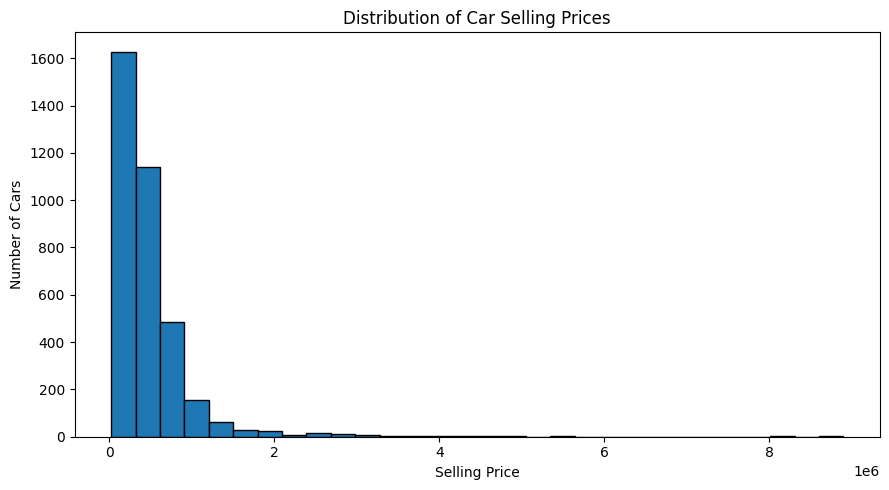

In [6]:
plt.figure(figsize=(9, 5))

plt.hist(df["selling_price"], bins=30, edgecolor="black")

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

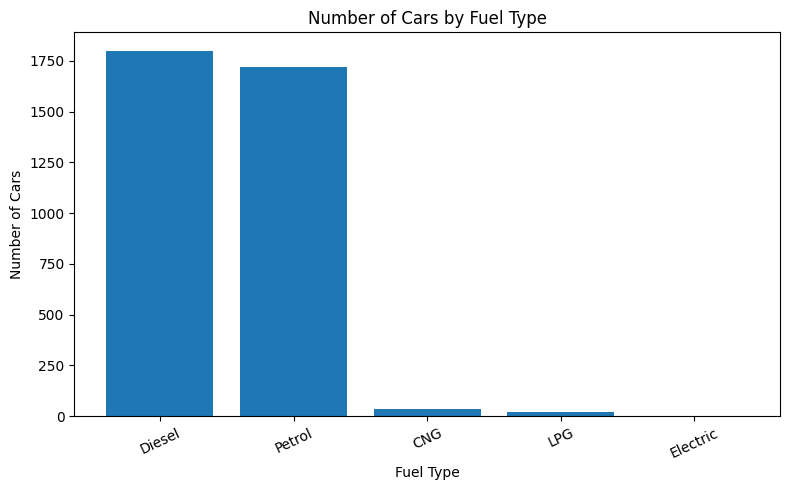

In [7]:
fuel_counts = df["fuel"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(fuel_counts.index, fuel_counts.values)

plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

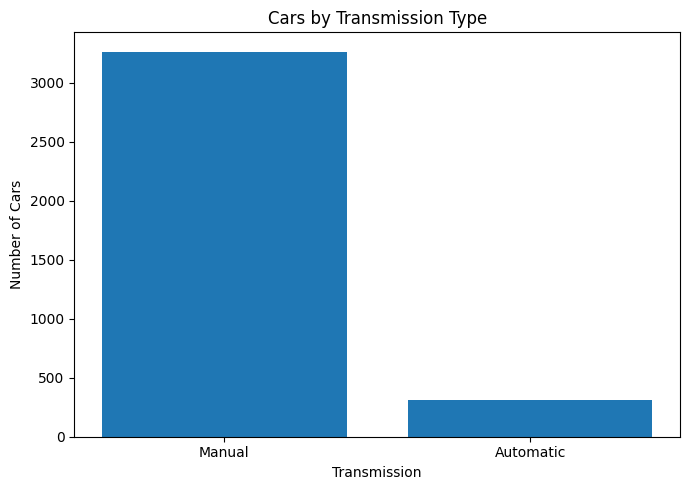

In [8]:
transmission_counts = df["transmission"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(
    transmission_counts.index,
    transmission_counts.values
)

plt.title("Cars by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

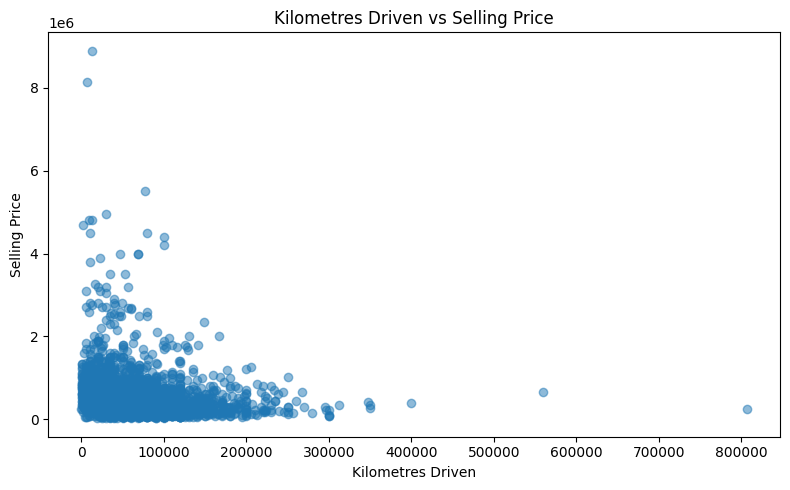

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["km_driven"],
    df["selling_price"],
    alpha=0.5
)

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.show()

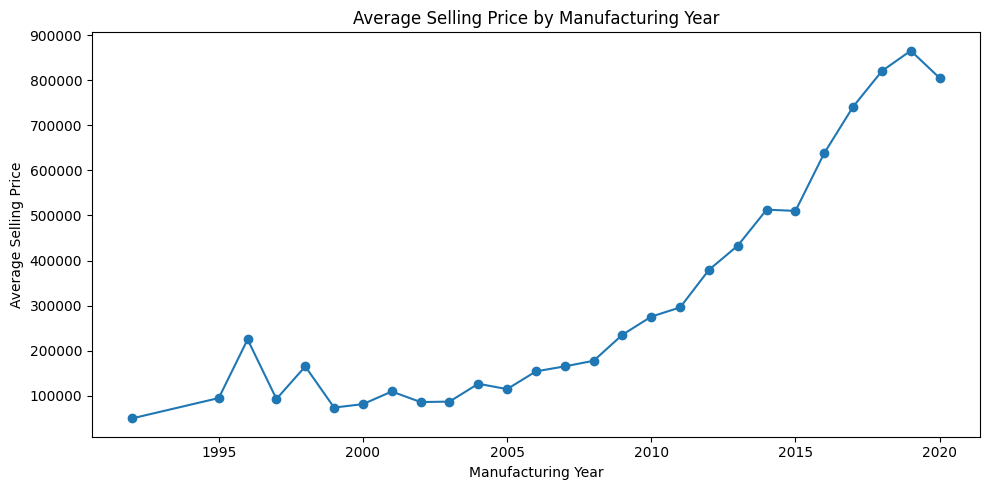

In [10]:
year_prices = df.groupby("year")["selling_price"].mean()

plt.figure(figsize=(10, 5))
plt.plot(year_prices.index, year_prices.values, marker="o")

plt.title("Average Selling Price by Manufacturing Year")
plt.xlabel("Manufacturing Year")
plt.ylabel("Average Selling Price")

plt.tight_layout()
plt.show()

## **10A. Statistical Analysis and Key Car Insights**

These additional operations extend the analysis with descriptive statistics, quartiles, outlier boundaries, most expensive cars, and key dataset counts.

In [ ]:
# Ensure core numeric columns are numeric before calculating statistics
for col in ["selling_price", "year", "km_driven", "car_age"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

price_series = df["selling_price"].dropna()

print("Dataset overview")
print("-" * 45)
print("Total car records:", len(df))
print("Unique car models:", df["name"].nunique() if "name" in df.columns else "N/A")
print("Unique brands:", df["brand"].nunique() if "brand" in df.columns else "N/A")
print("Average selling price: ₹{:,.2f}".format(price_series.mean()))
print("Median selling price: ₹{:,.2f}".format(price_series.median()))
print("Minimum selling price: ₹{:,.2f}".format(price_series.min()))
print("Maximum selling price: ₹{:,.2f}".format(price_series.max()))

print("\\nPrice statistics:")
display(price_series.describe().to_frame("selling_price").round(2))

q1 = price_series.quantile(0.25)
q2 = price_series.quantile(0.50)
q3 = price_series.quantile(0.75)
iqr = q3 - q1
print(f"Q1: ₹{q1:,.2f}")
print(f"Q2 / Median: ₹{q2:,.2f}")
print(f"Q3: ₹{q3:,.2f}")
print(f"IQR: ₹{iqr:,.2f}")
print(f"Lower outlier boundary: ₹{q1 - 1.5 * iqr:,.2f}")
print(f"Upper outlier boundary: ₹{q3 + 1.5 * iqr:,.2f}")


In [ ]:
# Additional car-specific counts and highest-priced records
if "seller_type" in df.columns:
    print("Cars by seller type:")
    display(df["seller_type"].value_counts(dropna=False).rename_axis("seller_type").to_frame("count"))

if "owner" in df.columns:
    print("\\nCars by ownership history:")
    display(df["owner"].value_counts(dropna=False).rename_axis("owner").to_frame("count"))

print("\\nTop 10 highest-priced cars:")
top_expensive_cars = df.nlargest(10, "selling_price")
display(top_expensive_cars[[
    c for c in ["name", "year", "selling_price", "km_driven", "fuel", "transmission"]
    if c in top_expensive_cars.columns
]].reset_index(drop=True))

print("\\nCar with the highest selling price:")
display(df.loc[[df["selling_price"].idxmax()], [
    c for c in ["name", "year", "selling_price", "km_driven", "fuel", "owner"]
    if c in df.columns
]])


## **10B. Additional Visualizations**

These plots add price distribution, brand comparison, price-versus-age, and top-car comparisons to the original EDA.

In [ ]:
# Histogram: selling-price distribution
plt.figure(figsize=(9, 5))
plt.hist(df["selling_price"].dropna(), bins=25, edgecolor="black")
plt.title("Distribution of Used-Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()


In [ ]:
# Pie chart: share of records among the 10 most common brands
brand_counts = df["brand"].value_counts().head(10)
if not brand_counts.empty:
    plt.figure(figsize=(8, 8))
    plt.pie(brand_counts.values, labels=brand_counts.index, autopct="%1.1f%%", startangle=90)
    plt.title("Top 10 Brands by Number of Listings")
    plt.tight_layout()
    plt.show()
else:
    print("Brand column is not available.")


In [ ]:
# Scatter plot: car age versus selling price
if "car_age" in df.columns:
    plot_df = df[["car_age", "selling_price"]].dropna()
    plt.figure(figsize=(8, 5))
    plt.scatter(plot_df["car_age"], plot_df["selling_price"], alpha=0.45)
    plt.title("Car Age vs Selling Price")
    plt.xlabel("Car Age (years)")
    plt.ylabel("Selling Price (₹)")
    plt.tight_layout()
    plt.show()


In [ ]:
# Line chart: average selling price by manufacturing year
yearly_avg = df.groupby("year")["selling_price"].mean().sort_index()
plt.figure(figsize=(10, 5))
plt.plot(yearly_avg.index, yearly_avg.values, marker="o")
plt.title("Average Used-Car Selling Price by Manufacturing Year")
plt.xlabel("Manufacturing Year")
plt.ylabel("Average Selling Price (₹)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
# Bar chart: 20 highest-priced car listings
top20_cars = df.nlargest(20, "selling_price").copy()
if not top20_cars.empty:
    labels = top20_cars["name"].astype(str).str.slice(0, 28)
    plt.figure(figsize=(12, 6))
    plt.bar(labels, top20_cars["selling_price"])
    plt.title("Top 20 Cars by Selling Price")
    plt.xlabel("Car Model")
    plt.ylabel("Selling Price (₹)")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()


## **10C. Export the Cleaned Dataset**

Save the processed dataset so it can be reused without repeating the cleaning and feature-engineering steps.

In [ ]:
# Save and verify the cleaned, feature-engineered dataset
FINAL_DATA_PATH = "cardekho_cleaned_final.csv"
df.to_csv(FINAL_DATA_PATH, index=False)

print("Final dataset saved to:", FINAL_DATA_PATH)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("\\nMissing values by column:")
display(df.isnull().sum().to_frame("missing_values"))
print("\\nDataset preview:")
display(df.head())

# In Google Colab, run this line to download the CSV:
# files.download(FINAL_DATA_PATH)


## **11. Correlation Analysis**

Correlation analysis measures the relationship between numerical variables. A correlation heatmap helps visualize the strength and direction of these relationships.

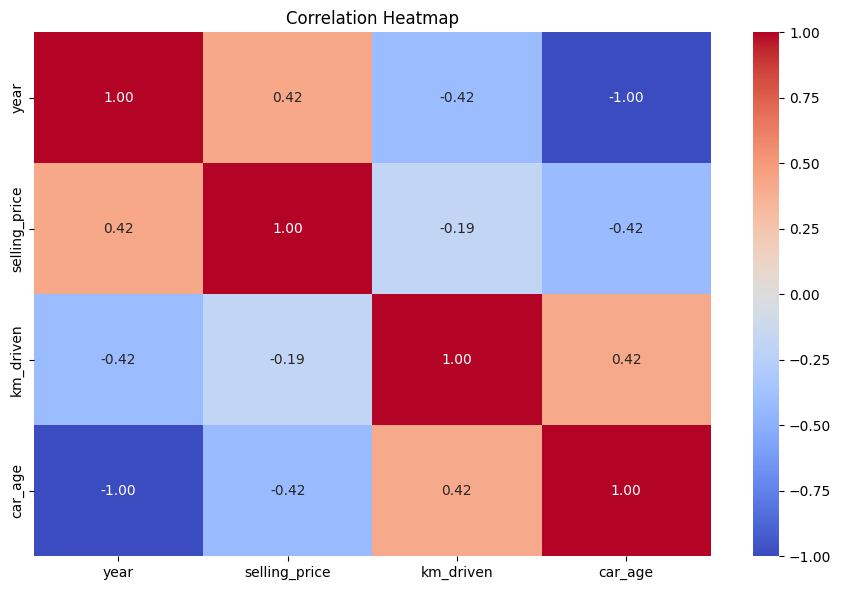

In [11]:
import seaborn as sns

numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

## **12. Data Preparation for Machine Learning**

The dataset is divided into input features and a target variable. The target variable is the selling price, while the remaining selected columns are used to predict it. Categorical variables are encoded before model training.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Select features and target
features = [
    "name",
    "year",
    "km_driven",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

X = df[features].copy()
y = df["selling_price"].copy()

numeric_features = ["year", "km_driven"]

categorical_features = [
    "name",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

# Preprocessing pipelines
numeric_transformer = SimpleImputer(strategy="median")

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Data preparation completed!")

Training records: 2861
Testing records: 716
Data preparation completed!


## **13. Model Training**

A Random Forest Regressor is used to predict used-car selling prices. It combines predictions from multiple decision trees to estimate the target value.

In [13]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## **14. Model Evaluation**

The trained model is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²). These metrics help measure the accuracy of selling-price predictions.

In [14]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): ₹{mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ₹{rmse:,.2f}")
print(f"R-squared Score (R²): {r2:.4f}")

Mean Absolute Error (MAE): ₹151,025.70
Root Mean Squared Error (RMSE): ₹398,486.60
R-squared Score (R²): 0.5071


## **15A. Compare Four Regression Models**

All models use the same train/test split and preprocessing. We compare MAE, RMSE, and R². The model with the lowest test RMSE is selected for the remaining prediction plots.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import clone

model_options = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

comparison_rows = []
trained_models = {}

for model_name, regressor in model_options.items():
    candidate = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", regressor)
    ])
    candidate.fit(X_train, y_train)
    predictions = candidate.predict(X_test)

    mae_value = mean_absolute_error(y_test, predictions)
    rmse_value = np.sqrt(mean_squared_error(y_test, predictions))
    r2_value = r2_score(y_test, predictions)

    comparison_rows.append({
        "Model": model_name,
        "MAE": mae_value,
        "RMSE": rmse_value,
        "R2": r2_value
    })
    trained_models[model_name] = candidate

comparison_df = pd.DataFrame(comparison_rows).sort_values("RMSE").reset_index(drop=True)
display(comparison_df.round(3))

best_model_name = comparison_df.loc[0, "Model"]
model = trained_models[best_model_name]
y_pred = model.predict(X_test)

print("Selected model:", best_model_name)
print("Reason: it has the lowest RMSE on the test set.")


## **15. Actual and Predicted Price Comparison**

Actual selling prices are compared with predicted prices to understand how closely the model estimates car values.

,Actual Price,Predicted Price
0,270000,407858.33
1,525000,494619.94
2,990000,660139.99
3,3800000,2020630.00
4,229999,157124.99
5,325000,271949.99
6,210000,142251.97
7,500000,634329.89
8,790000,887749.85
9,360000,236479.90


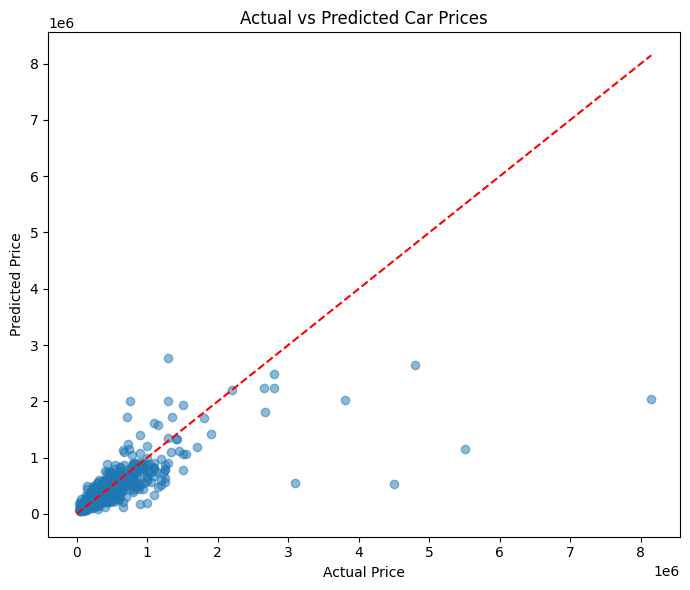

In [15]:
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(results.head(10).round(2))

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [0, max_price],
    [0, max_price],
    "r--"
)

plt.title("Actual vs Predicted Car Prices")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.tight_layout()
plt.show()

## **16. Streamlit Interactive Car Price Prediction System**

The complete user interface is built with Streamlit instead of Gradio. Run this cell to create `app.py` in the current folder. For a local Windows run, install the packages from `requirements.txt`, then run `python -m streamlit run app.py` from that folder.

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

st.set_page_config(page_title="AUTOVAULT | Used Car Price AI", page_icon="🚘", layout="wide")

st.markdown("""
<style>
.stApp {background:#101312;color:#f4f7f4}
[data-testid="stSidebar"] {background:#171d19}
h1,h2,h3 {color:#d5ff3f}
div[data-testid="stMetric"] {background:#1b241e;border:1px solid #394b30;padding:16px;border-radius:14px}
.stButton>button {background:#d5ff3f;color:#101312;border:0;border-radius:9px;font-weight:700}
</style>
""", unsafe_allow_html=True)

st.markdown("<h1>🚘 AUTOVAULT</h1><p>USED CAR PRICE ANALYSIS & PREDICTION</p>", unsafe_allow_html=True)
st.caption("Upload your CarDekho CSV to explore the market and estimate a car's resale price.")

uploaded = st.sidebar.file_uploader("Upload CarDekho CSV", type=["csv"])
if uploaded is None:
    st.info("Upload your dataset from the left sidebar to open the dashboard.")
    st.stop()

@st.cache_data(show_spinner=False)
def load_data(file_bytes):
    data = pd.read_csv(pd.io.common.BytesIO(file_bytes))
    data.columns = data.columns.str.strip().str.lower()
    return data

df = load_data(uploaded.getvalue())
required = ["name", "year", "selling_price", "km_driven", "fuel", "seller_type", "transmission", "owner"]
missing = [c for c in required if c not in df.columns]
if missing:
    st.error("Missing required columns: " + ", ".join(missing))
    st.write("Available columns:", df.columns.tolist())
    st.stop()

for col in ["year", "selling_price", "km_driven"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=["name", "year", "selling_price", "km_driven"])
df = df[(df["selling_price"] > 0) & (df["km_driven"] >= 0)].copy()
if len(df) < 10:
    st.error("Please upload a dataset with at least 10 valid car records.")
    st.stop()

features = ["name", "year", "km_driven", "fuel", "seller_type", "transmission", "owner"]
X = df[features].copy()
y = df["selling_price"].copy()
numeric = ["year", "km_driven"]
categorical = ["name", "fuel", "seller_type", "transmission", "owner"]
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model_options = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}
scores, fitted = [], {}
with st.spinner("Training four simple regression models..."):
    for name, regressor in model_options.items():
        pipe = Pipeline([("preprocessor", preprocessor), ("regressor", regressor)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        scores.append({
            "Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R²": r2_score(y_test, pred)
        })
        fitted[name] = pipe
scores_df = pd.DataFrame(scores).sort_values("RMSE").reset_index(drop=True)
best_name = scores_df.loc[0, "Model"]
model = fitted[best_name]

c1, c2, c3 = st.columns(3)
c1.metric("Cars in dataset", f"{len(df):,}")
c2.metric("Average listed price", f"₹{df['selling_price'].mean():,.0f}")
c3.metric("Best model", best_name)
st.divider()

tab1, tab2, tab3 = st.tabs(["💰 Price Prediction", "📊 Market Dashboard", "🧪 Model Comparison"])

with tab1:
    st.subheader("Estimate a car's resale price")
    left, right = st.columns(2)
    with left:
        car_name = st.selectbox("Car model", sorted(df["name"].astype(str).unique()))
        year = st.slider("Manufacturing year", int(df["year"].min()), max(2026, int(df["year"].max())), int(df["year"].median()))
        km = st.number_input("Kilometres driven", min_value=0, value=30000, step=1000)
        fuel = st.selectbox("Fuel", sorted(df["fuel"].dropna().astype(str).unique()))
    with right:
        seller = st.selectbox("Seller type", sorted(df["seller_type"].dropna().astype(str).unique()))
        transmission = st.selectbox("Transmission", sorted(df["transmission"].dropna().astype(str).unique()))
        owner = st.selectbox("Previous owner", sorted(df["owner"].dropna().astype(str).unique()))
        st.write("")
        predict = st.button("PREDICT PRICE", use_container_width=True)
    if predict:
        item = pd.DataFrame([{
            "name": car_name, "year": year, "km_driven": km, "fuel": fuel,
            "seller_type": seller, "transmission": transmission, "owner": owner
        }])[features]
        estimate = max(0, float(model.predict(item)[0]))
        st.success(f"Estimated selling price: ₹{estimate:,.0f}  (₹{estimate/100000:.2f} lakh)")
        st.caption("This is a machine-learning estimate, not a guaranteed market price.")

with tab2:
    st.subheader("Explore the used-car market")
    a, b, c = st.columns(3)
    search = a.text_input("Search car name")
    fuel_filter = b.selectbox("Fuel filter", ["All"] + sorted(df["fuel"].dropna().astype(str).unique()))
    trans_filter = c.selectbox("Transmission filter", ["All"] + sorted(df["transmission"].dropna().astype(str).unique()))
    min_price, max_price = int(df["selling_price"].min()), int(df["selling_price"].max())
    price_range = st.slider("Selling price range (₹)", min_price, max_price, (min_price, max_price))
    view = df[df["selling_price"].between(price_range[0], price_range[1])]
    if search:
        view = view[view["name"].astype(str).str.contains(search, case=False, na=False)]
    if fuel_filter != "All":
        view = view[view["fuel"].astype(str) == fuel_filter]
    if trans_filter != "All":
        view = view[view["transmission"].astype(str) == trans_filter]
    st.write(f"Matching records: {len(view):,}")
    st.dataframe(view.head(500), use_container_width=True)
    st.download_button("Download filtered CSV", view.to_csv(index=False).encode("utf-8"), "filtered_cars.csv", "text/csv")
    fig, ax = plt.subplots()
    ax.hist(view["selling_price"], bins=25)
    ax.set_title("Selling price distribution")
    ax.set_xlabel("Selling price (₹)")
    ax.set_ylabel("Number of cars")
    st.pyplot(fig)
    plt.close(fig)

with tab3:
    st.subheader("Compare model performance")
    st.caption("Lower MAE/RMSE is better; higher R² is generally better.")
    st.dataframe(scores_df.round(3), use_container_width=True)
    fig, ax = plt.subplots()
    ax.bar(scores_df["Model"], scores_df["RMSE"])
    ax.set_ylabel("RMSE (₹)")
    ax.set_title("RMSE comparison (lower is better)")
    ax.tick_params(axis="x", rotation=20)
    st.pyplot(fig)
    plt.close(fig)
    st.success(f"Selected model: {best_name} — lowest test RMSE.")


The former Gradio prediction interface has been removed. Use the Streamlit app created by the previous cell.

In [19]:
df["brand"] = df["name"].astype(str).str.split().str[0].str.title()

print(df["brand"].value_counts().reindex(
    ["Audi", "Bmw"], fill_value=0
))

brand
Audi    31
Bmw     25
Name: count, dtype: int64


In [20]:
df.groupby("brand")["selling_price"].agg(
    ["count", "mean", "median", "min", "max"]
).loc[["Audi", "Bmw"]]

,count,mean,median,min,max
brand,,,,,
Audi,31,2.185452e+06,1580000.0,650000,8900000
Bmw,25,2.242800e+06,2150000.0,480000,4950000


In [21]:
print("AUDI MODELS AND PRICES")
display(
    df[df["brand"] == "Audi"]
    .groupby("name")["selling_price"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
)

print("BMW MODELS AND PRICES")
display(
    df[df["brand"] == "Bmw"]
    .groupby("name")["selling_price"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
)

AUDI MODELS AND PRICES


,count,mean,median
name,,,
Audi Q5 2.0 TDI,3,2.013333e+06,1350000.0
Audi Q3 2.0 TDI Quattro Premium Plus,3,1.433333e+06,1400000.0
Audi A6 2.0 TDI Premium Plus,2,1.385000e+06,1385000.0
Audi A6 2.0 TDI Design Edition,2,1.742500e+06,1742500.0
Audi Q5 3.0 TDI Quattro Technology,2,3.549500e+06,3549500.0
Audi Q3 35 TDI Quattro Technology,2,2.637500e+06,2637500.0
Audi A4 1.8 TFSI,1,1.200000e+06,1200000.0
Audi A4 35 TDI Premium Plus,1,3.256000e+06,3256000.0
Audi A4 35 TDI Premium,1,2.300000e+06,2300000.0


BMW MODELS AND PRICES


,count,mean,median
name,,,
BMW 3 Series 320d Luxury Line,3,2.216667e+06,2200000.0
BMW 5 Series 520d Luxury Line,3,4.166667e+06,4800000.0
BMW X1 sDrive 20d xLine,3,2.583333e+06,2600000.0
BMW X1 sDrive20d,3,7.800000e+05,750000.0
BMW 7 Series 730Ld,3,1.750000e+06,1700000.0
BMW 3 Series 320d Sport,2,1.745000e+06,1745000.0
BMW 5 Series 525d Sedan,1,1.200000e+06,1200000.0
BMW 3 Series GT Luxury Line,1,3.050000e+06,3050000.0
BMW 3 Series 320d Sport Line,1,1.550000e+06,1550000.0


## **17. Interactive Dataset Explorer**

The Streamlit app includes the dataset explorer, search and filters, price distribution chart, filtered CSV download, and model-comparison table. Open the **Market Dashboard** and **Model Comparison** tabs in the app.

The previous Gradio explorer has been replaced by the Streamlit tabs in `app.py`.